# EDA Dataset Tugas Akhir

Notebook ini mengeksplorasi **NHANES** (ordinal), **Pen Digits** (klasifikasi), dan **Superconductivity** (regresi kontinu). Pemeriksaan meliputi kualitas data, distribusi target, fitur, korelasi, dan komposisi split.

Analisis seluruh dataset bersifat deskriptif. Gunakan hanya train dan validation untuk memilih fitur dan model; simpan test untuk evaluasi akhir. Nama fitur NHANES masih anonim dan definisi aslinya perlu diverifikasi.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit, train_test_split

sns.set_theme(style="whitegrid", context="notebook")
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "datasets.json").is_file()), None)
if root is None:
    raise FileNotFoundError("Buka notebook dari folder 4-augmentasi-input atau subfoldernya.")
config = json.loads((root / "config" / "datasets.json").read_text())
specs = {item["name"]: item for item in config["datasets"]}
def read_dataset(spec):
    frames = [pd.read_csv(root / spec["csv"])]
    if spec.get("test_csv"):
        frames.append(pd.read_csv(root / spec["test_csv"]))
    return pd.concat(frames, ignore_index=True)

data = {name: read_dataset(spec) for name, spec in specs.items()}
print(f"Folder proyek: {root}")

Folder proyek: /mnt/new-volume/Kuliah/Riset deep learning/4-augmentasi-input


## 1. Gambaran umum dan kualitas data

Jumlah fitur tidak memasukkan kolom target. Duplikasi dihitung untuk seluruh kolom, termasuk target.

In [2]:
overview = []
for name, df in data.items():
    target = specs[name]["target"]
    features = df.drop(columns=target)
    overview.append({
        "dataset": name, "baris": len(df), "fitur": features.shape[1],
        "fitur numerik": len(features.select_dtypes(include="number").columns),
        "kelas/level": df[target].nunique(), "sel kosong": df.isna().sum().sum(),
        "baris duplikat": df.duplicated().sum(),
        "fitur konstan": (features.nunique(dropna=False) <= 1).sum(),
    })
display(pd.DataFrame(overview).set_index("dataset"))

,baris,fitur,fitur numerik,kelas/level,sel kosong,baris duplikat,fitur konstan
dataset,,,,,,,
nhanes,5223,30,30,5,0,0,0
pendigits,10992,16,16,10,0,0,0
superconductivity,21263,81,81,3007,0,66,0


In [3]:
for name, df in data.items():
    print(f"\n{name.upper()} — lima baris pertama")
    display(df.head())
    print("Tipe data:")
    display(df.dtypes.value_counts().rename("jumlah kolom").to_frame())


NHANES — lima baris pertama


,x_0,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,...,x_21,x_22,x_23,x_24,x_25,x_26,x_27,x_28,x_29,y
0,2.0,2.0,2.0,1.0,1.0,63.0,764.0,765.0,4.0,1.0,...,1.0,2.0,2.0,1.0,2.0,7750.960967,7851.548119,2.0,67.0,0
1,2.0,2.0,2.0,1.0,2.0,43.0,520.0,521.0,3.0,1.0,...,1.0,2.0,2.0,1.0,2.0,80250.366559,82537.635085,2.0,68.0,0
2,2.0,2.0,2.0,2.0,1.0,35.0,423.0,424.0,5.0,5.0,...,1.0,2.0,2.0,1.0,2.0,77499.847246,79515.783969,2.0,67.0,0
3,1.0,2.0,1.0,1.0,1.0,52.0,625.0,625.0,3.0,1.0,...,1.0,2.0,2.0,1.0,2.0,30452.298415,31708.884317,2.0,65.0,0
4,1.0,2.0,2.0,1.0,2.0,16.0,194.0,195.0,1.0,1.0,...,1.0,2.0,2.0,1.0,2.0,10159.925574,10351.074548,1.0,70.0,0


Tipe data:


,jumlah kolom
float64,30
int64,1



PENDIGITS — lima baris pertama


,coord_1,coord_2,coord_3,coord_4,coord_5,coord_6,coord_7,coord_8,coord_9,coord_10,coord_11,coord_12,coord_13,coord_14,coord_15,coord_16,digit
0,47,100,27,81,57,37,26,0,0,23,56,53,100,90,40,98,8
1,0,89,27,100,42,75,29,45,15,15,37,0,69,2,100,6,2
2,0,57,31,68,72,90,100,100,76,75,50,51,28,25,16,0,1
3,0,100,7,92,5,68,19,45,86,34,100,45,74,23,67,0,4
4,0,67,49,83,100,100,81,80,60,60,40,40,33,20,47,0,1


... (2 outputs left out)


SUPERCONDUCTIVITY — lima baris pertama


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


Tipe data:


,jumlah kolom
float64,79
int64,3


## 2. Missing value dan duplikasi

Jumlah missing dihitung per kolom. Baris duplikat tidak langsung dihapus karena bisa merupakan observasi yang sah.

In [4]:
for name, df in data.items():
    missing = df.isna().sum().rename("jumlah").to_frame()
    missing["persen"] = missing["jumlah"] / len(df) * 100
    print(f"\n{name.upper()} — kolom dengan missing value")
    display(missing[missing["jumlah"] > 0] if missing["jumlah"].any() else pd.DataFrame({"keterangan": ["Tidak ada missing value"]}))
    print(f"Baris duplikat identik: {df.duplicated().sum()}")


NHANES — kolom dengan missing value


,keterangan
0,Tidak ada missing value


Baris duplikat identik: 0

PENDIGITS — kolom dengan missing value


,keterangan
0,Tidak ada missing value


Baris duplikat identik: 0

SUPERCONDUCTIVITY — kolom dengan missing value


,keterangan
0,Tidak ada missing value


Baris duplikat identik: 66


## 3. Distribusi target

NHANES memiliki level ordinal dan dievaluasi menggunakan QWK. Pen Digits adalah klasifikasi dan menggunakan macro-F1. Superconductivity mempertahankan `critical_temp` sebagai target kontinu dan menggunakan MSE.


NHANES — distribusi target


,jumlah,persen
y,,
0,560,10.72
1,1471,28.16
2,2071,39.65
3,927,17.75
4,194,3.71



PENDIGITS — distribusi target


,jumlah,persen
digit,,
0,1143,10.40
1,1143,10.40
2,1144,10.41
3,1055,9.60
4,1144,10.41
5,1055,9.60
6,1056,9.61
7,1142,10.39
8,1055,9.60



SUPERCONDUCTIVITY — distribusi target


,critical_temp
count,21263.000000
mean,34.421219
std,34.254362
min,0.000210
25%,5.365000
50%,20.000000
75%,63.000000
max,185.000000


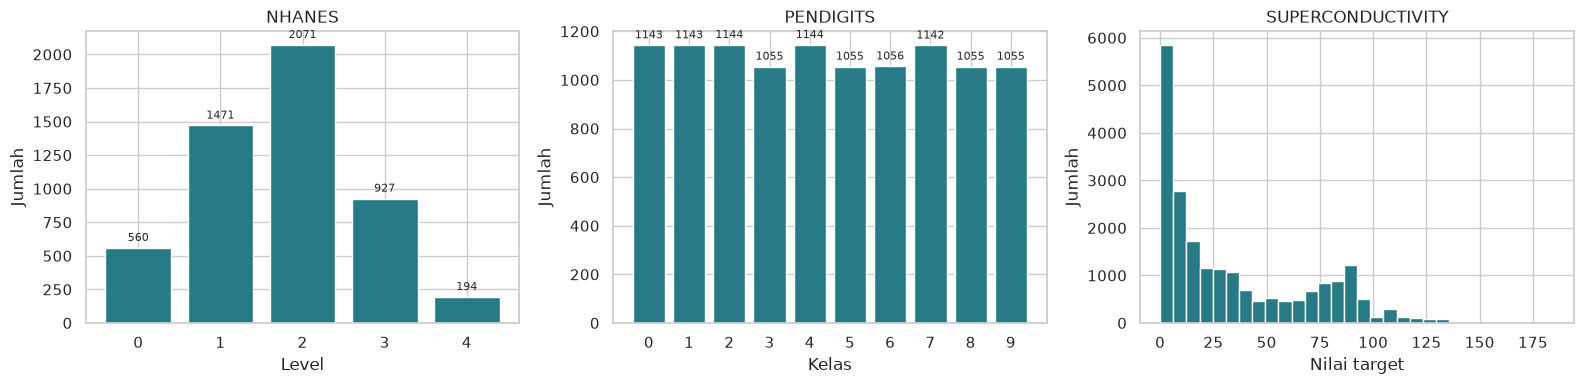

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, df) in zip(axes, data.items()):
    spec = specs[name]
    target = spec["target"]
    print(f"\n{name.upper()} — distribusi target")
    if spec["task_type"] == "regression":
        display(df[target].describe().to_frame())
        ax.hist(df[target], bins=30, color="#287b86", edgecolor="white")
        ax.set(xlabel="Nilai target", ylabel="Jumlah")
    else:
        counts = df[target].value_counts().sort_index()
        table = pd.DataFrame({"jumlah": counts, "persen": (counts / len(df) * 100).round(2)})
        display(table)
        ax.bar(counts.index.astype(str), counts.values, color="#287b86")
        ax.set(xlabel="Level" if spec["task_type"] == "ordinal_regression" else "Kelas", ylabel="Jumlah")
        ax.bar_label(ax.containers[0], padding=3, fontsize=8)
    ax.set_title(name.upper())
fig.tight_layout()
plt.show()

## 4. Statistik dan distribusi fitur

Tabel memuat seluruh fitur numerik. Histogram menampilkan enam fitur pertama sebagai sampel; pilihan ini bukan seleksi fitur untuk model.

In [6]:
for name, df in data.items():
    print(f"\n{name.upper()} — statistik deskriptif")
    display(df.drop(columns=specs[name]["target"]).describe().T)


NHANES — statistik deskriptif


,count,mean,std,min,25%,50%,75%,max
x_0,5223.0,1.833429,0.527505,1.000000e+00,2.000000,2.000000,2.000000,9.000000
x_1,5223.0,1.905993,0.326549,1.000000e+00,2.000000,2.000000,2.000000,9.000000
x_2,5223.0,1.965920,0.359777,1.000000e+00,2.000000,2.000000,2.000000,9.000000
x_3,5223.0,1.545280,0.497993,1.000000e+00,1.000000,2.000000,2.000000,2.000000
x_4,5223.0,1.497607,0.500042,1.000000e+00,1.000000,1.000000,2.000000,2.000000
x_5,5223.0,42.921310,19.653708,1.100000e+01,25.000000,43.000000,60.000000,79.000000
x_6,5223.0,520.444955,235.908683,1.420000e+02,309.000000,521.000000,726.000000,958.000000
x_7,5223.0,521.271683,235.888605,1.440000e+02,309.500000,522.000000,727.000000,959.000000
x_8,5223.0,2.816963,1.095149,1.000000e+00,2.000000,3.000000,4.000000,5.000000
x_9,5223.0,1.503733,1.127600,1.000000e+00,1.000000,1.000000,1.000000,5.000000



PENDIGITS — statistik deskriptif


,count,mean,std,min,25%,50%,75%,max
coord_1,10992.0,38.814320,34.257783,0.0,6.0,32.0,65.0,100.0
coord_2,10992.0,85.120269,16.218571,0.0,76.0,89.0,100.0,100.0
coord_3,10992.0,40.605622,26.342984,0.0,20.0,40.0,58.0,100.0
coord_4,10992.0,83.774199,19.163646,0.0,72.0,91.0,100.0,100.0
coord_5,10992.0,49.770378,34.100515,0.0,18.0,53.0,78.0,100.0
coord_6,10992.0,65.573144,26.996688,0.0,49.0,71.0,86.0,100.0
coord_7,10992.0,51.220251,30.576881,0.0,28.0,53.5,74.0,100.0
coord_8,10992.0,44.498999,29.906104,0.0,23.0,43.0,64.0,100.0
coord_9,10992.0,56.868541,34.135530,0.0,29.0,60.0,89.0,100.0
coord_10,10992.0,33.695961,27.251548,0.0,7.0,33.0,54.0,100.0



SUPERCONDUCTIVITY — statistik deskriptif


,count,mean,std,min,25%,50%,75%,max
number_of_elements,21263.0,4.115224,1.439295,1.000000,3.000000,4.000000,5.000000,9.000000
mean_atomic_mass,21263.0,87.557631,29.676497,6.941000,72.458076,84.922750,100.404410,208.980400
wtd_mean_atomic_mass,21263.0,72.988310,33.490406,6.423452,52.143839,60.696571,86.103540,208.980400
gmean_atomic_mass,21263.0,71.290627,31.030272,5.320573,58.041225,66.361592,78.116681,208.980400
wtd_gmean_atomic_mass,21263.0,58.539916,36.651067,1.960849,35.248990,39.918385,73.113234,208.980400
...,...,...,...,...,...,...,...,...
wtd_entropy_Valence,21263.0,1.052841,0.380291,0.000000,0.775678,1.166532,1.330801,1.949739
range_Valence,21263.0,2.041010,1.242345,0.000000,1.000000,2.000000,3.000000,6.000000
wtd_range_Valence,21263.0,1.483007,0.978176,0.000000,0.921454,1.063077,1.918400,6.992200
std_Valence,21263.0,0.839342,0.484676,0.000000,0.451754,0.800000,1.200000,3.000000


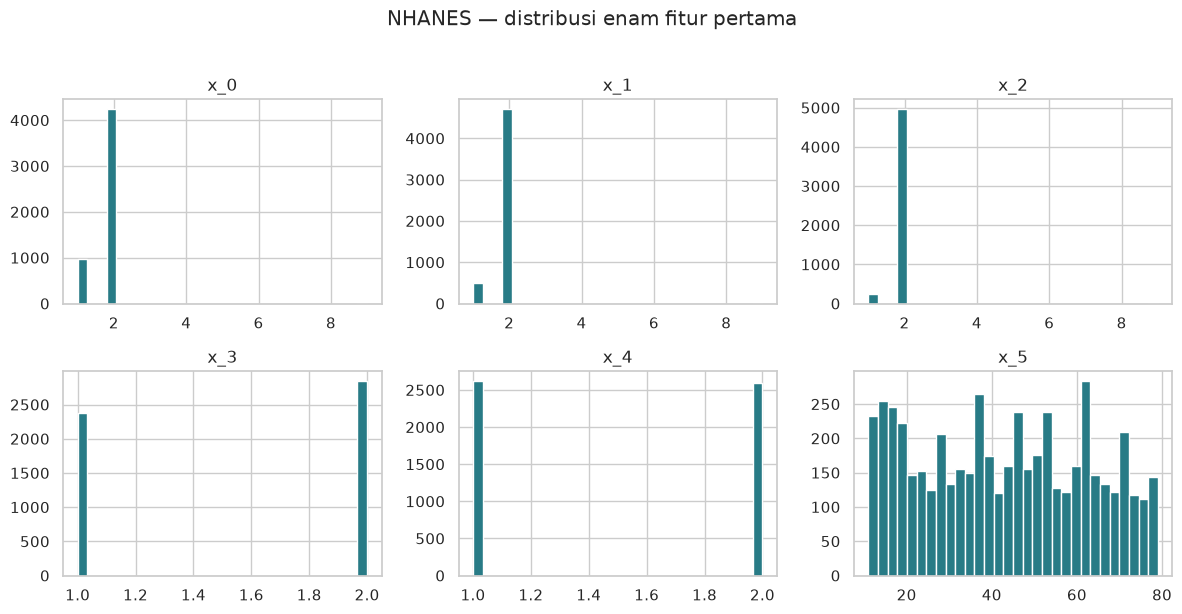

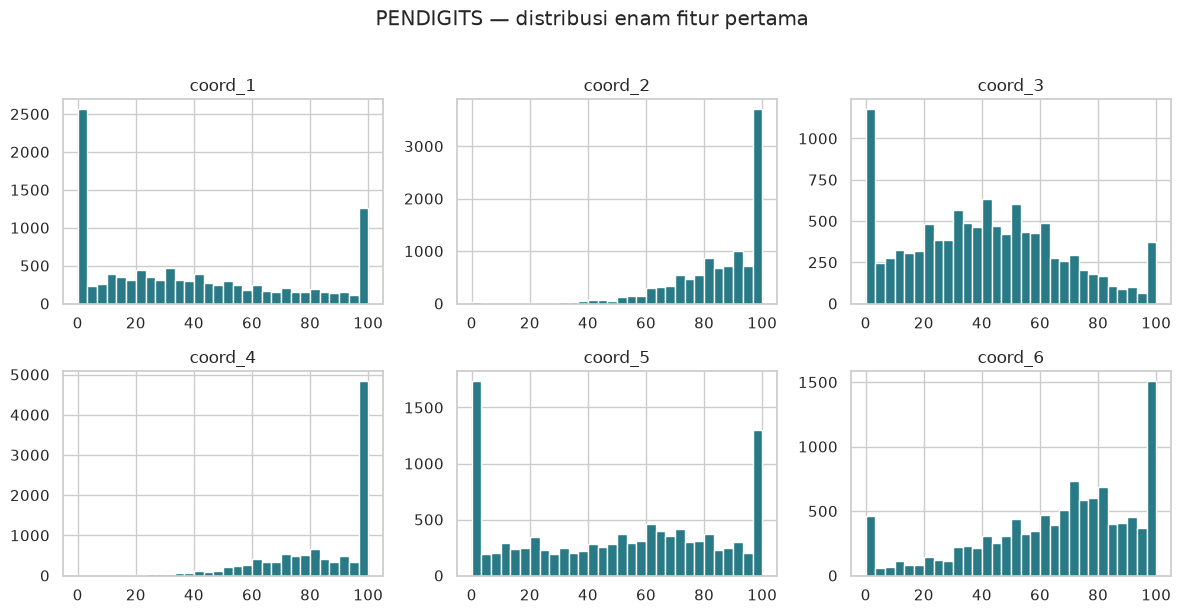

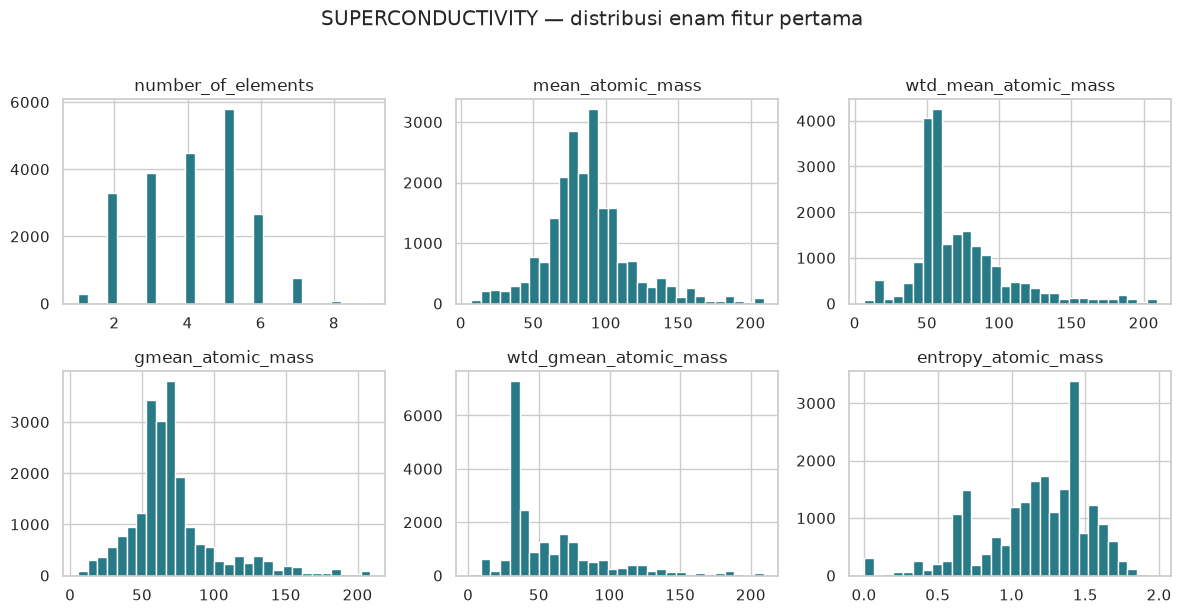

In [7]:
for name, df in data.items():
    features = df.drop(columns=specs[name]["target"]).select_dtypes(include="number")
    axes = features.iloc[:, :6].hist(bins=30, figsize=(12, 6), layout=(2, 3), color="#287b86", edgecolor="white")
    plt.suptitle(f"{name.upper()} — distribusi enam fitur pertama", y=1.02)
    plt.tight_layout()
    plt.show()

## 5. Korelasi antarf​​itur

Korelasi Pearson mengukur hubungan linear; nilai tinggi tidak membuktikan sebab-akibat. Periksa definisi fitur sebelum memutuskan apakah suatu fitur perlu dihapus.

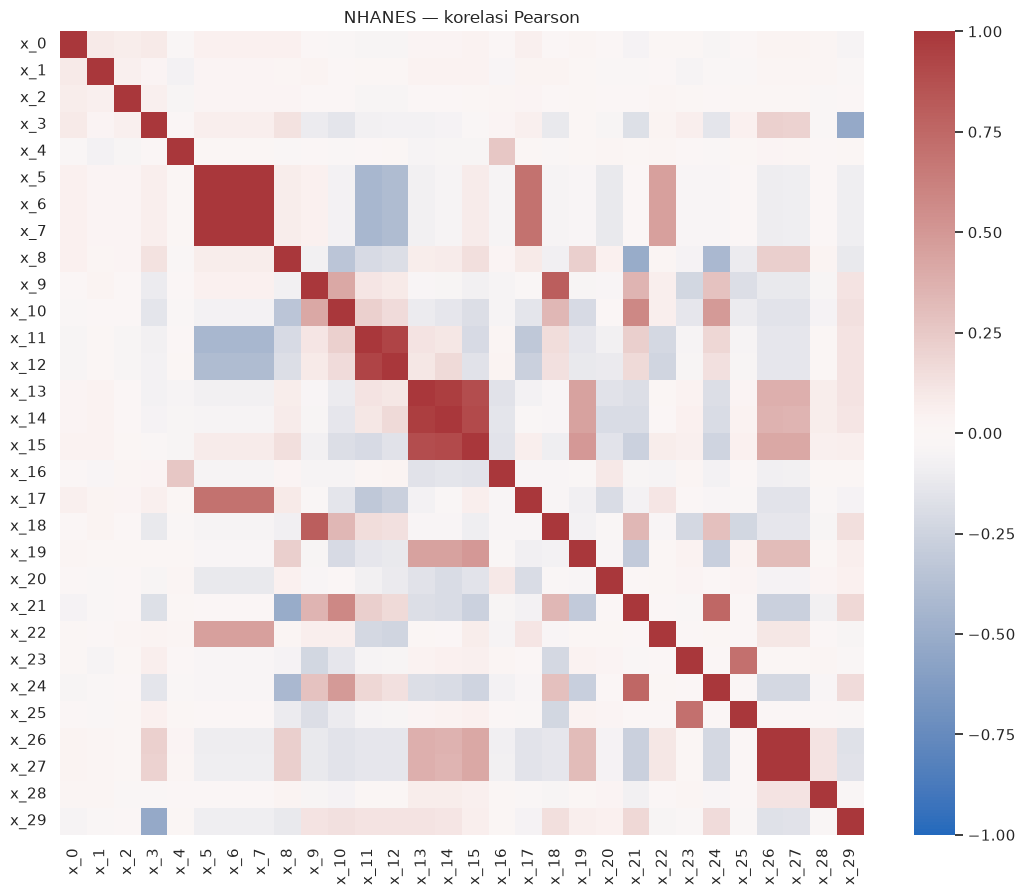

NHANES — 10 pasangan korelasi absolut terbesar


,fitur 1,fitur 2,korelasi
159,x_6,x_7,0.999997
135,x_5,x_6,0.999895
136,x_5,x_7,0.999892
429,x_26,x_27,0.998536
299,x_13,x_14,0.964099
264,x_11,x_12,0.930975
315,x_14,x_15,0.906058
300,x_13,x_15,0.890317
233,x_9,x_18,0.800772
401,x_21,x_24,0.754987


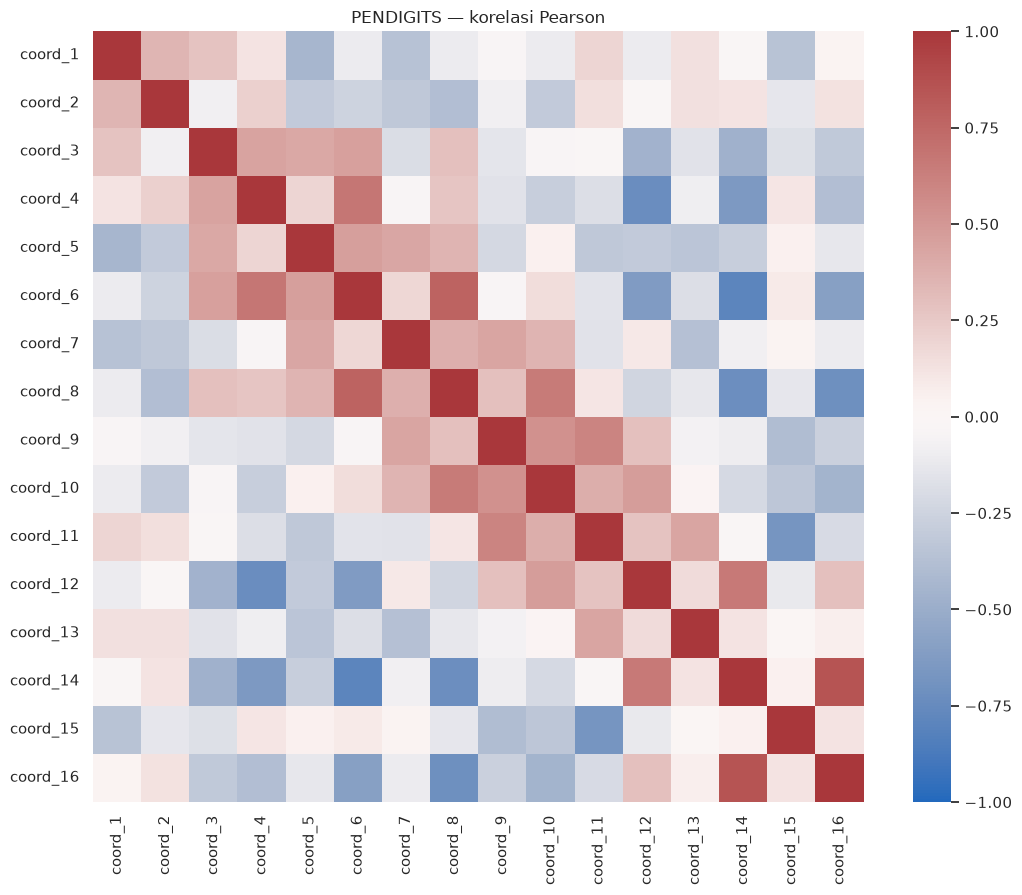

PENDIGITS — 10 pasangan korelasi absolut terbesar


,fitur 1,fitur 2,korelasi
118,coord_14,coord_16,0.857205
72,coord_6,coord_14,-0.794761
66,coord_6,coord_8,0.779892
49,coord_4,coord_12,-0.732677
89,coord_8,coord_14,-0.719883
91,coord_8,coord_16,-0.711123
108,coord_11,coord_15,-0.677238
43,coord_4,coord_6,0.675734
111,coord_12,coord_14,0.659548
85,coord_8,coord_10,0.650526


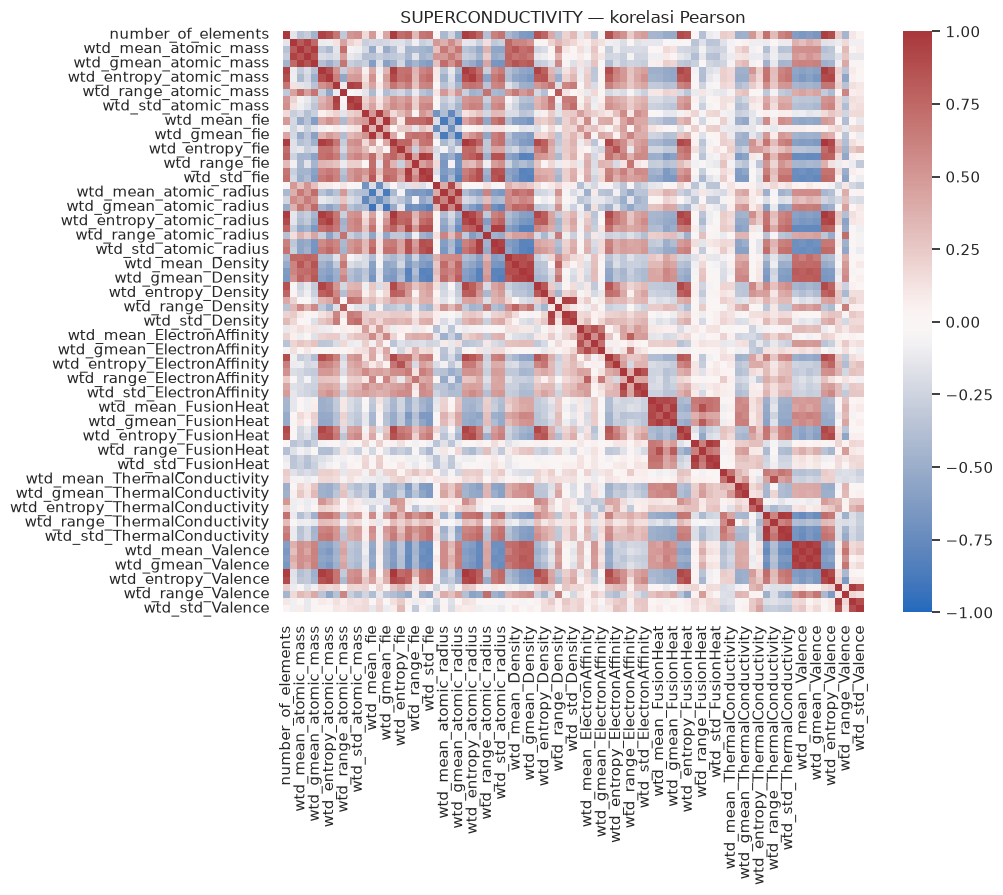

SUPERCONDUCTIVITY — 10 pasangan korelasi absolut terbesar


,fitur 1,fitur 2,korelasi
1104,entropy_fie,entropy_atomic_radius,0.997739
3205,wtd_mean_Valence,wtd_gmean_Valence,0.994939
1154,entropy_fie,entropy_Valence,0.992726
895,wtd_mean_fie,wtd_gmean_fie,0.992331
3196,mean_Valence,gmean_Valence,0.989911
1749,entropy_atomic_radius,entropy_Valence,0.989546
3150,range_ThermalConductivity,std_ThermalConductivity,0.987867
2965,range_FusionHeat,std_FusionHeat,0.984574
1225,range_fie,std_fie,0.981628
1530,wtd_mean_atomic_radius,wtd_gmean_atomic_radius,0.980107


In [8]:
for name, df in data.items():
    features = df.drop(columns=specs[name]["target"]).select_dtypes(include="number")
    corr = features.corr()
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, square=True)
    ax.set_title(f"{name.upper()} — korelasi Pearson")
    plt.tight_layout()
    plt.show()
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    pairs = upper.stack().rename("korelasi").reset_index()
    pairs.columns = ["fitur 1", "fitur 2", "korelasi"]
    print(f"{name.upper()} — 10 pasangan korelasi absolut terbesar")
    display(pairs.iloc[pairs["korelasi"].abs().argsort()[::-1]].head(10))

## 6. Komposisi split eksperimen

NHANES memakai split stratified. Pen Digits mempertahankan test resmi dan mengambil validation 20% dari train resmi secara stratified. Superconductivity memisahkan vektor fitur identik ke satu kelompok sebelum pembagian train/validation/test untuk mengurangi kebocoran.

Tabel menampilkan fraksi **10% dari train pool** sesuai konfigurasi EDA; training juga menggunakan 1% dan 30%. Label train-unlabeled hanya untuk pemeriksaan deskriptif dan tidak disimpan sebagai input training.

In [9]:
def split_indices(df, target, task_type, name):
    y = df[target]
    idx = np.arange(len(df))
    seed = config["seed"]
    spec = specs[name]
    continuous = task_type == "regression"
    if spec.get("test_csv"):
        train_size = len(pd.read_csv(root / spec["csv"]))
        trainval, test = idx[:train_size], idx[train_size:]
        train, val = train_test_split(trainval, test_size=spec["validation_fraction_of_official_train"], random_state=seed, stratify=y.iloc[trainval])
    elif spec.get("split_policy") == "group_by_features":
        groups = pd.util.hash_pandas_object(df.drop(columns=target), index=False).to_numpy()
        trainval, test = next(GroupShuffleSplit(n_splits=1, test_size=config["test_fraction"], random_state=seed).split(idx, groups=groups))
        tr, va = next(GroupShuffleSplit(n_splits=1, test_size=config["validation_fraction"] / (config["train_fraction"] + config["validation_fraction"]), random_state=seed).split(trainval, groups=groups[trainval]))
        train, val = trainval[tr], trainval[va]
    else:
        trainval, test = train_test_split(idx, test_size=config["test_fraction"], random_state=seed, stratify=None if continuous else y)
        train, val = train_test_split(trainval, test_size=config["validation_fraction"] / (config["train_fraction"] + config["validation_fraction"]), random_state=seed, stratify=None if continuous else y.iloc[trainval])
    labeled, unlabeled = train_test_split(train, test_size=1 - config["labeled_fraction"], random_state=seed, stratify=None if continuous else y.iloc[train])
    return {"labeled": labeled, "unlabeled": unlabeled, "validation": val, "test": test}

for name, df in data.items():
    spec = specs[name]
    target = spec["target"]
    parts = split_indices(df, target, spec["task_type"], name)
    print(f"\n{name.upper()} — split")
    if spec["task_type"] == "regression":
        display(pd.DataFrame({part: {"jumlah": len(idx), "rata-rata target": df.iloc[idx][target].mean()} for part, idx in parts.items()}))
    else:
        table = pd.concat({part: df.iloc[idx][target].value_counts().sort_index() for part, idx in parts.items()}, axis=1).fillna(0).astype(int)
        table.loc["total"] = table.sum()
        display(table)


NHANES — split


,labeled,unlabeled,validation,test
y,,,,
0,39,353,84,84
1,103,926,221,221
2,145,1304,311,311
3,65,584,139,139
4,13,123,29,29
total,365,3290,784,784



PENDIGITS — split


,labeled,unlabeled,validation,test
digit,,,,
0,62,562,156,363
1,62,561,156,364
2,62,562,156,364
3,57,518,144,336
4,62,562,156,364
5,58,518,144,335
6,58,518,144,336
7,62,561,155,364
8,58,517,144,336



SUPERCONDUCTIVITY — split


,labeled,unlabeled,validation,test
jumlah,1500.000000,13506.000000,3176.000000,3081.000000
rata-rata target,35.247647,34.834207,34.379899,32.251071


## 7. Catatan untuk eksperimen

- **NHANES:** level terjarang hanya memiliki satu contoh pada 1% labeled train. Verifikasi arti fitur dan target sebelum interpretasi substantif.
- **Pen Digits:** test resmi berisi penulis berbeda. Validation diambil dari train resmi; identitas penulis tidak tersedia untuk memisahkan penulis di train dan validation.
- **Superconductivity:** `critical_temp` tetap kontinu. Banyak baris memiliki vektor fitur yang sama; split berbasis kelompok mencegah fitur identik muncul di partisi train, validation, dan test, tetapi tidak menjamin pemisahan seluruh kelompok material yang serupa.
- QWK, macro-F1, dan MSE dihitung pada test setelah pemilihan konfigurasi menggunakan validation.